<a href="https://colab.research.google.com/github/AngelStrg/MachineLearning/blob/main/Unidad_3/Proyecto_Unidad2_SVR_Asesinatos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto Unidad 2: Análisis Predictivo de la Tasa de Asesinatos
## Algoritmo: SVR (Support Vector Regression)

**Variable objetivo (Y):** `tasa_asesinatos_por_100mil`
**Métrica principal:** Coeficiente de determinación (R²)

Contenido:
1. Carga y exploración de datos
2. Regresión Lineal Múltiple (baseline, necesaria para comparar con SVR lineal)
3. SVR: Ejecución 1 (kernel RBF) y Ejecución 2 (kernel Linear), con variables iniciales y con variables seleccionadas
4. Exploración de parámetros (kernel, C, gamma, epsilon)
5. Importancia de variables (permutation importance)
6. Resumen comparativo y conclusiones

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42


## 1. Carga de datos

In [ ]:
# Sube el archivo DATASET_Asesinatos.csv cuando lo pida Colab
# (si ya lo subiste al panel de archivos, no hace falta volver a subirlo)
import os
if not os.path.exists("DATASET_Asesinatos.csv"):
    from google.colab import files
    files.upload()

# El archivo está codificado en latin-1 (por los acentos de los nombres de estados)
df = pd.read_csv("DATASET_Asesinatos.csv", encoding="latin-1")
print("Dimensiones:", df.shape)
df.head()

Dimensiones: (3000, 16)


,Estado,id_area,habitantes,area_km2,ingresos_medios,edad_media_poblacion,densidad_poblacional,indice_gini,tasa_desempleo_juvenil,porcentaje_sin_diploma_secundaria,porcentaje_hogares_monoparentales,gasto_policial_per_capita,inversion_programas_sociales_per_capita,tiempo_respuesta_emergencias_min,porcentaje_zonas_verdes,tasa_asesinatos_por_100mil
0,Puebla,1,207953,26.70,48018,40.8,7787.47,0.522,21.8,30.3,40.0,867,240,3.0,5.0,27.1
1,Durango,2,80226,17.39,50295,42.4,4612.66,0.346,19.2,18.9,23.5,706,458,3.0,11.1,13.6
2,Tabasco,3,260806,70.69,50795,39.5,3689.22,0.417,23.0,33.5,23.8,981,403,4.3,8.1,20.6
3,Baja California Sur,4,969508,830.49,68910,27.3,1167.39,0.399,28.8,17.7,23.5,951,326,7.5,16.1,18.5
4,Aguascalientes,5,69478,30.59,54248,36.2,2271.26,0.422,16.4,33.6,27.6,563,353,7.2,10.6,16.8


In [ ]:
print("Valores nulos por columna:")
print(df.isna().sum()[df.isna().sum() > 0] if df.isna().sum().sum() else "Sin valores nulos")
df.describe().T

Valores nulos por columna:
Sin valores nulos


,count,mean,std,min,25%,50%,75%,max
id_area,3000.0,1500.500000,866.169729,1.000,750.750,1500.500,2250.2500,3000.00
habitantes,3000.0,262654.719333,413727.481480,5000.000,38510.000,102389.500,271138.5000,2000000.00
area_km2,3000.0,96.967677,172.700026,10.000,12.125,33.960,96.0575,2207.18
ingresos_medios,3000.0,60298.995333,13220.705234,30000.000,51384.750,58931.000,67677.2500,121378.00
edad_media_poblacion,3000.0,36.915533,4.859472,25.000,33.600,36.900,40.2000,53.90
densidad_poblacional,3000.0,2991.633247,1711.261226,500.000,1814.545,2656.710,3773.4425,14640.99
indice_gini,3000.0,0.422485,0.052641,0.253,0.387,0.422,0.4580,0.63
tasa_desempleo_juvenil,3000.0,19.637433,4.976529,5.600,16.100,19.700,23.2000,30.00
porcentaje_sin_diploma_secundaria,3000.0,25.123100,9.912250,5.000,18.100,24.900,32.0000,50.00
porcentaje_hogares_monoparentales,3000.0,25.648100,5.097224,10.000,22.075,25.600,29.2000,40.00


### Exploración: correlación con la variable objetivo

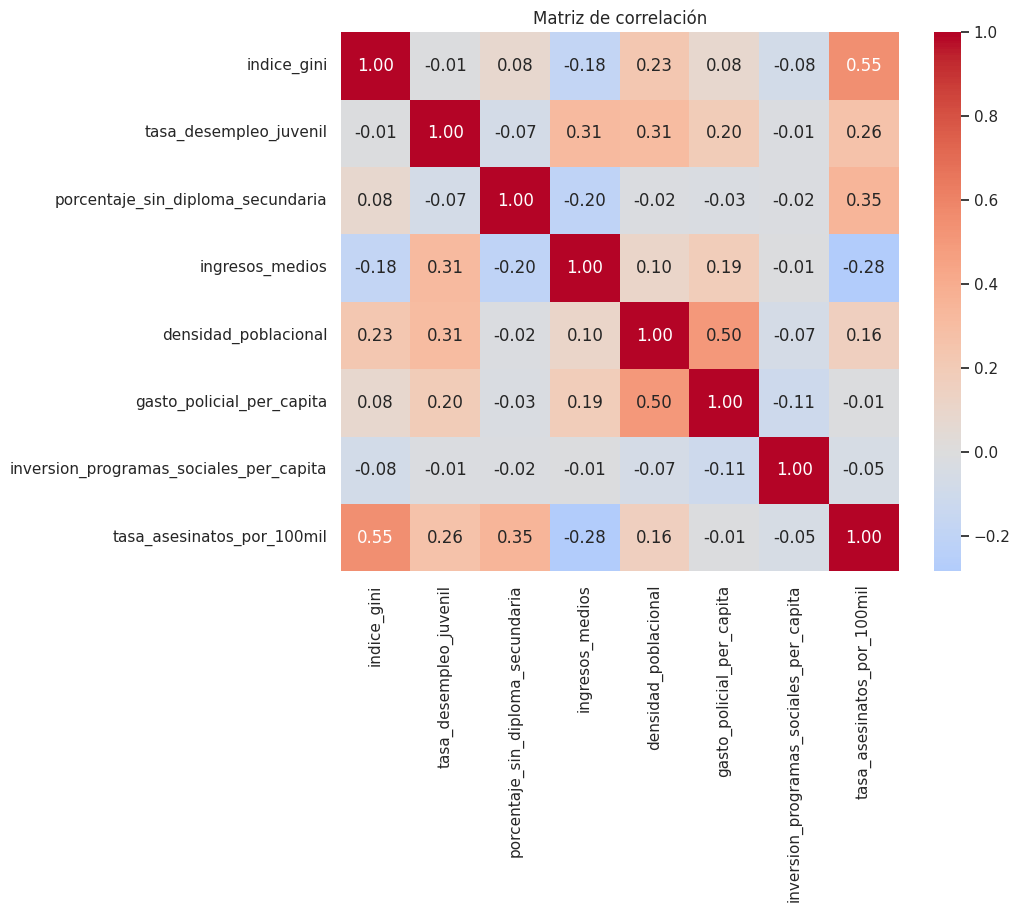

Correlación con la variable objetivo:
indice_gini                                0.551
porcentaje_sin_diploma_secundaria          0.346
tasa_desempleo_juvenil                     0.262
densidad_poblacional                       0.165
gasto_policial_per_capita                 -0.012
inversion_programas_sociales_per_capita   -0.051
ingresos_medios                           -0.284
Name: tasa_asesinatos_por_100mil, dtype: float64


In [ ]:
TARGET = "tasa_asesinatos_por_100mil"

VARS_INICIALES = [
    "indice_gini",
    "tasa_desempleo_juvenil",
    "porcentaje_sin_diploma_secundaria",
    "ingresos_medios",
    "densidad_poblacional",
    "gasto_policial_per_capita",
    "inversion_programas_sociales_per_capita",
]

corr = df[VARS_INICIALES + [TARGET]].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlación")
plt.show()

print("Correlación con la variable objetivo:")
print(corr[TARGET].drop(TARGET).sort_values(ascending=False).round(3))

## 2. Preparación de datos y Regresión Lineal Múltiple

Se utiliza una división de 80% de los datos para entrenamiento y 20% para prueba. Para los modelos SVR, las variables predictoras se escalan mediante StandardScaler, ajustando el escalador únicamente con los datos de entrenamiento para evitar fuga de información.

Además de las siete variables iniciales, se utiliza un subconjunto de cuatro variables seleccionadas para comparar el desempeño de los modelos.

In [ ]:
# Variables seleccionadas para la segunda ejecución
VARS_SELECCIONADAS = [
    "indice_gini",
    "tasa_desempleo_juvenil",
    "porcentaje_sin_diploma_secundaria",
    "ingresos_medios"
]

# Variable objetivo
y = df[TARGET]

# Función para preparar los datos
def preparar(variables):
    X = df[variables]

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=RANDOM_STATE
    )

    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    return X_train, X_test, X_train_scaled, X_test_scaled, y_train, y_test, scaler


# Preparación con las 7 variables iniciales
X_tr, X_te, A_tr, A_te, y_tr, y_te, scaler = preparar(VARS_INICIALES)

# Preparación con las 4 variables seleccionadas
X_tr2, X_te2, A_tr2, A_te2, y_tr2, y_te2, scaler2 = preparar(VARS_SELECCIONADAS)

print("Datos preparados correctamente")
print("Entrenamiento:", len(y_tr))
print("Prueba:", len(y_te))

Datos preparados correctamente
Entrenamiento: 2400
Prueba: 600


### 2.1 Regresión Lineal Múltiple (RLM) como modelo base

Se utiliza la Regresión Lineal Múltiple como modelo de referencia para posteriormente comparar su desempeño con el SVR de kernel linear.

Se realizan dos ejecuciones: una con las siete variables iniciales y otra con las cuatro variables seleccionadas.

In [ ]:
# Función para evaluar los modelos
def evaluar(modelo, X_train, X_test, y_train, y_test):
    pred_train = modelo.predict(X_train)
    pred_test = modelo.predict(X_test)

    return {
        "R2_train": r2_score(y_train, pred_train),
        "R2_test": r2_score(y_test, pred_test),
        "RMSE_test": np.sqrt(mean_squared_error(y_test, pred_test))
    }


# Lista donde se guardarán los resultados de todos los modelos
resultados = []


# RLM con las 7 variables iniciales
rlm = LinearRegression()
rlm.fit(A_tr, y_tr)

r = evaluar(rlm, A_tr, A_te, y_tr, y_te)

resultados.append({
    "Modelo": "RLM",
    "Variables": "Iniciales (7)",
    **r
})


# RLM con las 4 variables seleccionadas
rlm2 = LinearRegression()
rlm2.fit(A_tr2, y_tr2)

r = evaluar(rlm2, A_tr2, A_te2, y_tr2, y_te2)

resultados.append({
    "Modelo": "RLM",
    "Variables": "Seleccionadas (4)",
    **r
})


# Mostrar resultados
pd.DataFrame(resultados).round(4)

,Modelo,Variables,R2_train,R2_test,RMSE_test
0,RLM,Iniciales (7),0.5336,0.5533,3.0011
1,RLM,Seleccionadas (4),0.5284,0.5505,3.0105


In [ ]:
# Coeficientes de la RLM con las variables iniciales
coef = pd.Series(rlm.coef_, index=VARS_INICIALES)

tabla_coef = pd.DataFrame({
    "Variable": VARS_INICIALES,
    "Coeficiente": rlm.coef_
})

tabla_coef["Efecto"] = np.where(
    tabla_coef["Coeficiente"] > 0,
    "Positivo",
    "Negativo"
)

tabla_coef["Magnitud"] = tabla_coef["Coeficiente"].abs()

tabla_coef = tabla_coef.sort_values(
    "Magnitud",
    ascending=False
).drop(columns="Magnitud")

display(tabla_coef.round(4))

,Variable,Coeficiente,Efecto
0,indice_gini,2.1104,Positivo
1,tasa_desempleo_juvenil,1.6046,Positivo
2,porcentaje_sin_diploma_secundaria,1.2746,Positivo
3,ingresos_medios,-0.9976,Negativo
5,gasto_policial_per_capita,-0.3170,Negativo
6,inversion_programas_sociales_per_capita,-0.0952,Negativo
4,densidad_poblacional,-0.0077,Negativo


## 3. SVR (Support Vector Regression)

**Paso preliminar obligatorio:** el SVR es sensible a la escala, por lo que las variables X se escalan con `StandardScaler` (ya hecho en `preparar()`; el escalador se ajusta solo con el conjunto de entrenamiento para evitar fuga de información).

### 3.1 Ejecución 1: kernel RBF

In [ ]:
# ---- SVR RBF, variables iniciales ----
svr_rbf = SVR(kernel="rbf").fit(A_tr, y_tr)
r = evaluar(svr_rbf, A_tr, A_te, y_tr, y_te)
resultados.append({"Modelo": "SVR RBF (defecto)", "Variables": "Iniciales (7)", **r})

# ---- SVR RBF, variables seleccionadas ----
svr_rbf2 = SVR(kernel="rbf").fit(A_tr2, y_tr2)
r = evaluar(svr_rbf2, A_tr2, A_te2, y_tr2, y_te2)
resultados.append({"Modelo": "SVR RBF (defecto)", "Variables": "Seleccionadas (4)", **r})

pd.DataFrame(resultados).tail(2).round(4)

,Modelo,Variables,R2_train,R2_test,RMSE_test
2,SVR RBF (defecto),Iniciales (7),0.5463,0.5166,3.1220
3,SVR RBF (defecto),Seleccionadas (4),0.5318,0.5219,3.1049


### 3.2 Ejecución 2: kernel Linear (y comparación con la RLM)

In [ ]:
# ---- SVR Linear, variables iniciales ----
svr_lin = SVR(kernel="linear").fit(A_tr, y_tr)
r = evaluar(svr_lin, A_tr, A_te, y_tr, y_te)
resultados.append({"Modelo": "SVR Linear", "Variables": "Iniciales (7)", **r})

# ---- SVR Linear, variables seleccionadas ----
svr_lin2 = SVR(kernel="linear").fit(A_tr2, y_tr2)
r = evaluar(svr_lin2, A_tr2, A_te2, y_tr2, y_te2)
resultados.append({"Modelo": "SVR Linear", "Variables": "Seleccionadas (4)", **r})

tabla = pd.DataFrame(resultados).round(4)
tabla

,Modelo,Variables,R2_train,R2_test,RMSE_test
0,RLM,Iniciales (7),0.5336,0.5533,3.0011
1,RLM,Seleccionadas (4),0.5284,0.5505,3.0105
2,SVR RBF (defecto),Iniciales (7),0.5463,0.5166,3.1220
3,SVR RBF (defecto),Seleccionadas (4),0.5318,0.5219,3.1049
4,SVR Linear,Iniciales (7),0.5332,0.5554,2.9942
5,SVR Linear,Seleccionadas (4),0.5279,0.5509,3.0091


In [ ]:
# Comparación directa SVR Linear vs RLM (R2 en prueba)
comp = tabla[tabla["Modelo"].isin(["RLM", "SVR Linear"])][["Modelo", "Variables", "R2_test"]]
print(comp.to_string(index=False))

# Los coeficientes del SVR lineal también son interpretables
coef_svr = pd.Series(svr_lin.coef_.ravel(), index=VARS_INICIALES)
comp_coef = pd.DataFrame({"RLM": pd.Series(rlm.coef_, index=VARS_INICIALES), "SVR Linear": coef_svr}).round(3)
comp_coef

    Modelo         Variables  R2_test
       RLM     Iniciales (7)   0.5533
       RLM Seleccionadas (4)   0.5505
SVR Linear     Iniciales (7)   0.5554
SVR Linear Seleccionadas (4)   0.5509


,RLM,SVR Linear
indice_gini,2.110,2.136
tasa_desempleo_juvenil,1.605,1.659
porcentaje_sin_diploma_secundaria,1.275,1.251
ingresos_medios,-0.998,-1.012
densidad_poblacional,-0.008,0.033
gasto_policial_per_capita,-0.317,-0.346
inversion_programas_sociales_per_capita,-0.095,-0.065


## 4. Exploración de parámetros (kernel, C, gamma, epsilon)

Se prueban distintos kernels y valores de **C** (penalización del error), y luego una búsqueda en malla con validación cruzada (5 folds) para el kernel RBF.

In [ ]:
filas = []
for kernel in ["linear", "rbf", "poly"]:
    for C in [0.1, 1, 10, 100]:
        m = SVR(kernel=kernel, C=C).fit(A_tr, y_tr)
        filas.append({
            "kernel": kernel, "C": C,
            "R2_train": r2_score(y_tr, m.predict(A_tr)),
            "R2_test": r2_score(y_te, m.predict(A_te)),
        })
explor = pd.DataFrame(filas)
explor["brecha (train-test)"] = explor["R2_train"] - explor["R2_test"]
explor.round(4)

,kernel,C,R2_train,R2_test,brecha (train-test)
0,linear,0.1,0.5333,0.5549,-0.0217
1,linear,1.0,0.5332,0.5554,-0.0221
2,linear,10.0,0.5332,0.5554,-0.0223
3,linear,100.0,0.5332,0.5554,-0.0222
4,rbf,0.1,0.4416,0.4403,0.0013
5,rbf,1.0,0.5463,0.5166,0.0297
6,rbf,10.0,0.6220,0.4882,0.1338
7,rbf,100.0,0.7089,0.3857,0.3232
8,poly,0.1,0.4252,0.4101,0.0152
9,poly,1.0,0.4459,0.3966,0.0493


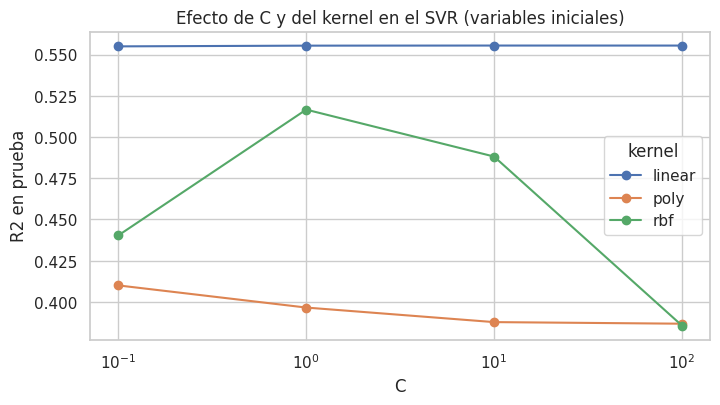

In [ ]:
pivot = explor.pivot(index="C", columns="kernel", values="R2_test")
pivot.plot(marker="o", figsize=(8, 4))
plt.xscale("log")
plt.ylabel("R2 en prueba")
plt.title("Efecto de C y del kernel en el SVR (variables iniciales)")
plt.show()

In [ ]:
# Búsqueda en malla para SVR RBF con validación cruzada

# Pipeline: el escalamiento se realiza dentro de cada partición
# de la validación cruzada para evitar fuga de información
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svr", SVR(kernel="rbf"))
])

# Valores de los hiperparámetros que se van a probar
param_grid = {
    "svr__C": [0.1, 1, 10, 100],
    "svr__gamma": ["scale", 0.01, 0.1],
    "svr__epsilon": [0.1, 0.5, 1.0]
}

# Validación cruzada de 5 particiones
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Búsqueda de la mejor combinación
grid = GridSearchCV(
    pipeline,
    param_grid,
    cv=cv,
    scoring="r2",
    n_jobs=-1
)

# Se usan los datos originales porque el Pipeline
# realiza el escalamiento automáticamente
grid.fit(X_tr, y_tr)

print("Mejores parámetros:", grid.best_params_)
print(f"R2 validación cruzada: {grid.best_score_:.4f}")

# Mejor modelo encontrado
mejor = grid.best_estimator_

# Evaluación final con entrenamiento y prueba
r = evaluar(
    mejor,
    X_tr,
    X_te,
    y_tr,
    y_te
)

resultados.append({
    "Modelo": "SVR RBF (ajustado CV)",
    "Variables": "Iniciales (7)",
    **r
})

print(f"R2 train: {r['R2_train']:.4f} | R2 test: {r['R2_test']:.4f}")

Mejores parámetros: {'svr__C': 1, 'svr__epsilon': 0.1, 'svr__gamma': 0.01}
R2 validación cruzada: 0.5232
R2 train: 0.5312 | R2 test: 0.5471


## 5. Importancia de variables (permutation importance)

Importancia de variables en SVR RBF:
indice_gini                                0.4604
tasa_desempleo_juvenil                     0.2468
porcentaje_sin_diploma_secundaria          0.1344
ingresos_medios                            0.1201
gasto_policial_per_capita                  0.0114
densidad_poblacional                       0.0007
inversion_programas_sociales_per_capita   -0.0022
dtype: float64


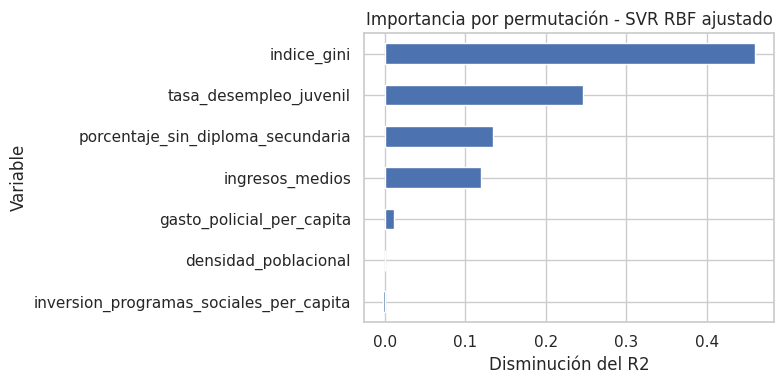


Top 3 RLM: ['indice_gini', 'tasa_desempleo_juvenil', 'porcentaje_sin_diploma_secundaria']
Top 3 SVR: ['indice_gini', 'tasa_desempleo_juvenil', 'porcentaje_sin_diploma_secundaria']


In [ ]:
# El SVR con kernel RBF no tiene coeficientes directos,
# por lo que se utiliza importancia por permutación.
# Esta técnica mide cuánto disminuye el R2 al alterar cada variable.

pi = permutation_importance(
    mejor,
    X_te,
    y_te,
    n_repeats=30,
    random_state=RANDOM_STATE,
    scoring="r2"
)

imp = pd.Series(
    pi.importances_mean,
    index=VARS_INICIALES
).sort_values(ascending=False)

print("Importancia de variables en SVR RBF:")
print(imp.round(4))

# Gráfica
imp.sort_values().plot(
    kind="barh",
    figsize=(8, 4)
)

plt.title("Importancia por permutación - SVR RBF ajustado")
plt.xlabel("Disminución del R2")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

# Comparación de las 3 variables más importantes
print("\nTop 3 RLM:",
      list(coef.abs().sort_values(ascending=False).index[:3]))

print("Top 3 SVR:",
      list(imp.index[:3]))

## 6. Visualización: valores reales vs. predichos

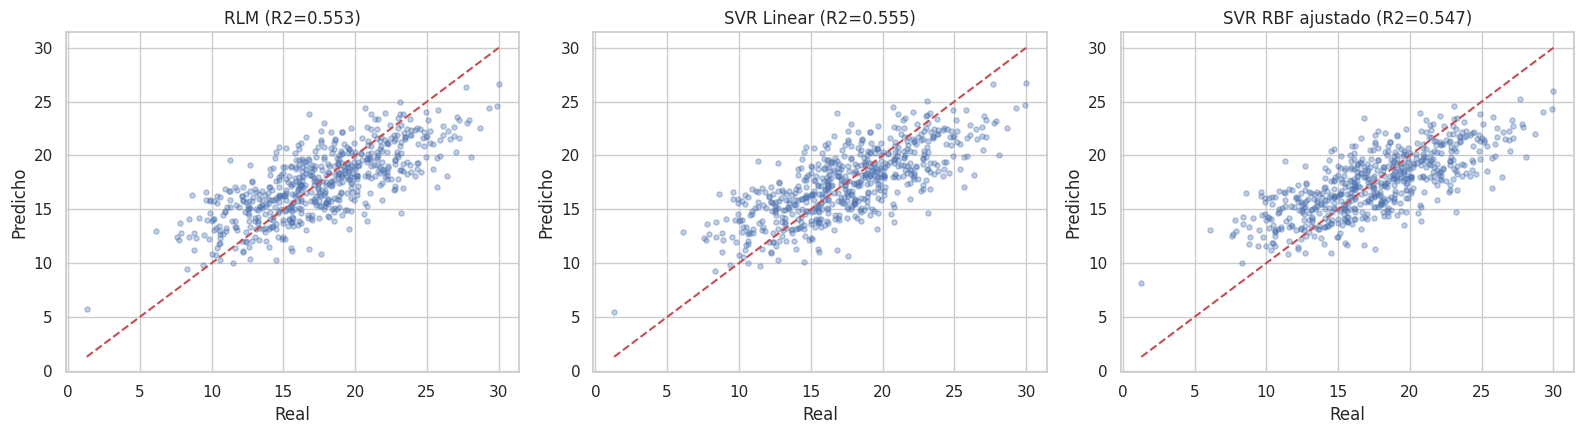

In [ ]:
# Visualización de valores reales vs. predichos

fig, ejes = plt.subplots(1, 3, figsize=(16, 4.5))

# RLM
pred_rlm = rlm.predict(A_te)

ejes[0].scatter(y_te, pred_rlm, alpha=0.35, s=14)
lim = [y_te.min(), y_te.max()]
ejes[0].plot(lim, lim, "r--")
ejes[0].set_title(f"RLM (R2={r2_score(y_te, pred_rlm):.3f})")
ejes[0].set_xlabel("Real")
ejes[0].set_ylabel("Predicho")


# SVR Linear
pred_lin = svr_lin.predict(A_te)

ejes[1].scatter(y_te, pred_lin, alpha=0.35, s=14)
ejes[1].plot(lim, lim, "r--")
ejes[1].set_title(f"SVR Linear (R2={r2_score(y_te, pred_lin):.3f})")
ejes[1].set_xlabel("Real")
ejes[1].set_ylabel("Predicho")


# SVR RBF ajustado
# Se utiliza X_te porque el Pipeline realiza el escalamiento internamente
pred_rbf = mejor.predict(X_te)

ejes[2].scatter(y_te, pred_rbf, alpha=0.35, s=14)
ejes[2].plot(lim, lim, "r--")
ejes[2].set_title(f"SVR RBF ajustado (R2={r2_score(y_te, pred_rbf):.3f})")
ejes[2].set_xlabel("Real")
ejes[2].set_ylabel("Predicho")

plt.tight_layout()
plt.show()

## 7. Resumen comparativo

,Modelo,Variables,R2_train,R2_test,RMSE_test
0,RLM,Iniciales (7),0.5336,0.5533,3.0011
1,RLM,Seleccionadas (4),0.5284,0.5505,3.0105
2,SVR RBF (defecto),Iniciales (7),0.5463,0.5166,3.1220
3,SVR RBF (defecto),Seleccionadas (4),0.5318,0.5219,3.1049
4,SVR Linear,Iniciales (7),0.5332,0.5554,2.9942
5,SVR Linear,Seleccionadas (4),0.5279,0.5509,3.0091
6,SVR RBF (ajustado CV),Iniciales (7),0.5312,0.5471,3.0220



Mejor R2 en prueba: 0.5554 -> SVR Linear (Iniciales (7))


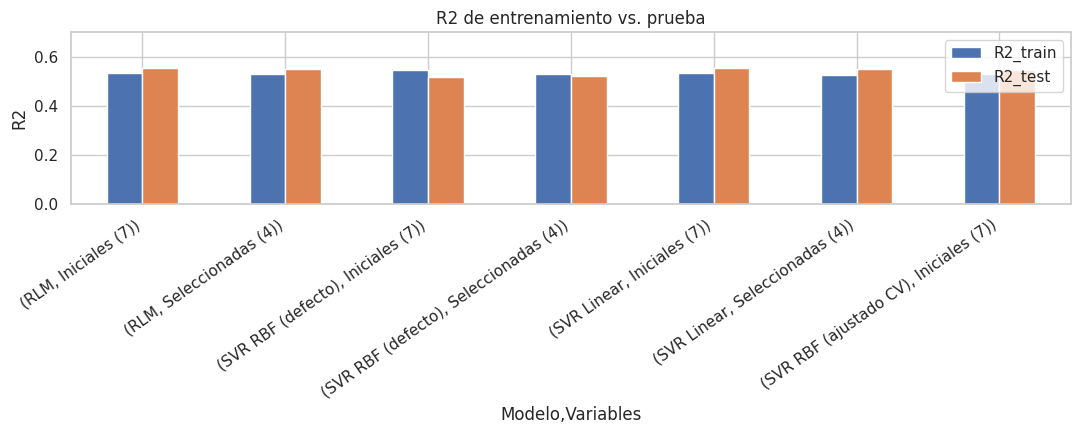

In [ ]:
resumen = pd.DataFrame(resultados).round(4)
display(resumen)

mejor_fila = resumen.loc[resumen["R2_test"].idxmax()]
print(f"\nMejor R2 en prueba: {mejor_fila['R2_test']} -> {mejor_fila['Modelo']} ({mejor_fila['Variables']})")

resumen.set_index(["Modelo", "Variables"])[["R2_train", "R2_test"]].plot(
    kind="bar",
    figsize=(11, 4.5)
)

plt.ylabel("R2")
plt.title("R2 de entrenamiento vs. prueba")
plt.xticks(rotation=35, ha="right")
plt.ylim(0, 0.7)
plt.tight_layout()
plt.show()

## 8. Conclusiones

**1. Comparación entre SVR RBF y SVR Linear.**  
Al comparar las configuraciones evaluadas, el SVR con kernel Linear y las siete variables iniciales obtuvo el mejor resultado, con un R² de prueba de 0.5554 y un RMSE de 2.9942. En comparación, el SVR RBF por defecto obtuvo un R² de 0.5166 con las siete variables y de 0.5219 con las cuatro variables seleccionadas. Por lo tanto, en este conjunto de datos el uso del kernel RBF no produjo una mejora frente al kernel Linear.

**2. Comparación con la Regresión Lineal Múltiple.**  
La Regresión Lineal Múltiple con las siete variables obtuvo un R² de prueba de 0.5533, mientras que el SVR Linear alcanzó 0.5554. La diferencia es pequeña, pero el SVR Linear presentó el mejor desempeño predictivo de los modelos evaluados. Estos resultados indican que, para las variables y configuraciones utilizadas, aumentar la complejidad mediante un kernel no lineal no generó una ventaja en la predicción.

**3. Selección de variables.**  
Se compararon las siete variables iniciales con un subconjunto formado por `indice_gini`, `tasa_desempleo_juvenil`, `porcentaje_sin_diploma_secundaria` e `ingresos_medios`. En SVR Linear, el R² pasó de 0.5554 con siete variables a 0.5509 con cuatro variables. En SVR RBF ocurrió lo contrario: el R² aumentó ligeramente de 0.5166 a 0.5219 al utilizar cuatro variables. Esto muestra que reducir el número de predictores puede mantener un rendimiento similar, aunque el mejor resultado general se obtuvo utilizando las siete variables con SVR Linear.

**4. Ajuste de hiperparámetros y sobreajuste.**  
La exploración de los parámetros mostró que aumentar el valor de `C` no garantiza una mejora en los datos de prueba. En algunas configuraciones del kernel RBF, el R² de entrenamiento aumentó mientras el R² de prueba disminuyó, lo que representa una señal de sobreajuste. Por esta razón, el rendimiento en entrenamiento no debe utilizarse de manera aislada para seleccionar el modelo.

**5. Validación cruzada y ajuste del SVR RBF.**  
Mediante GridSearchCV con validación cruzada de cinco particiones se seleccionaron como mejores parámetros `C=1`, `epsilon=0.1` y `gamma=0.01`. El modelo obtuvo un R² promedio de validación cruzada de 0.5232, un R² de entrenamiento de 0.5312 y un R² de prueba de 0.5471. Aunque el ajuste mejoró el resultado del RBF respecto a su configuración por defecto, no superó al SVR Linear.

**6. Importancia de variables.**  
La importancia por permutación del SVR RBF ajustado identificó como las tres variables más relevantes a `indice_gini` (0.4604), `tasa_desempleo_juvenil` (0.2468) y `porcentaje_sin_diploma_secundaria` (0.1344). Estas tres variables coinciden con las de mayor magnitud en la Regresión Lineal Múltiple, lo que aporta consistencia entre ambos métodos respecto a los factores con mayor capacidad predictiva dentro del conjunto de variables analizado.

**Conclusión general.**  
De los modelos evaluados, el SVR con kernel Linear y las siete variables iniciales presentó el mejor desempeño, con un R² de prueba de 0.5554 y un RMSE de 2.9942. Sin embargo, su ventaja respecto a la Regresión Lineal Múltiple fue pequeña. El ajuste mediante GridSearchCV mejoró considerablemente el desempeño del SVR RBF, pero no logró superar al modelo lineal. En consecuencia, para este conjunto de datos y bajo las configuraciones evaluadas, el SVR Linear representa la mejor alternativa predictiva entre los modelos analizados.